In [1]:
import os
import sys

sys.path.append("../src")
from training.plot import (
    plot_variance_per_feature,
    plot_average_feature_variance,
    plot_overall_ensemble_variance,
)
from data_processing.utils import compute_ensemble_variance_by_lead_time
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

from data_processing.load import load_windpower, load_evaluation_forecast_data
from data_processing.downtime import CapacityFactorTransformer
import pandas as pd

from data_processing.load import (
    load_windparks,
    load_windparks,
    load_weather_forecast_parquet,
    load_windpower,
    load_weather_nowcast,
)
import pandas as pd

from data_processing.load import (
    load_weather_forecast_parquet,
    load_windpower,
    load_weather_nowcast,
)

from data_processing.load import load_dataset
from configs.load_config import dict_to_namespace
from scipy.stats import spearmanr
import numpy as np
from configs.load_config import load_config
from types import SimpleNamespace

Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Renamed columns: 79
  Dropped columns: 15
  Final columns: 79

 RangeIndex(start=0, stop=6874212, step=1)


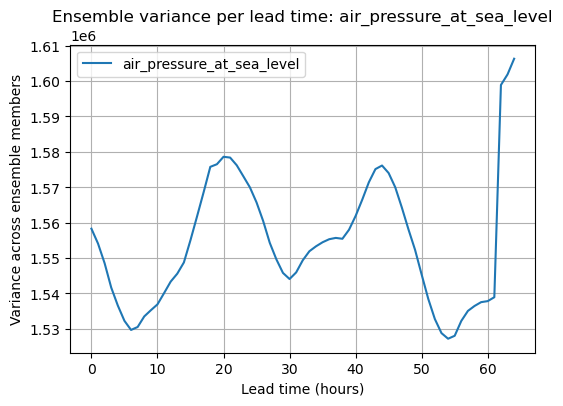

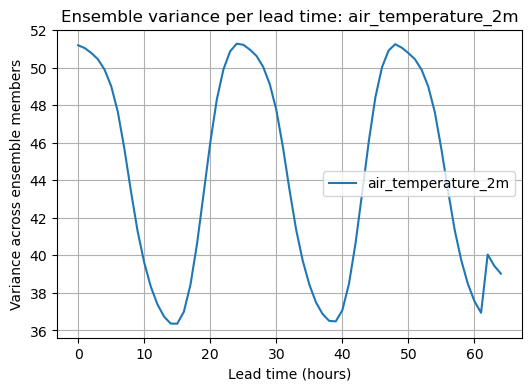

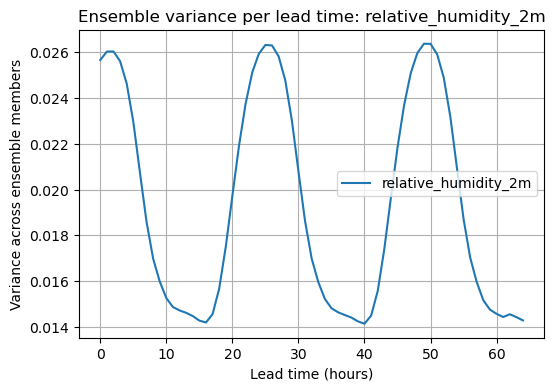

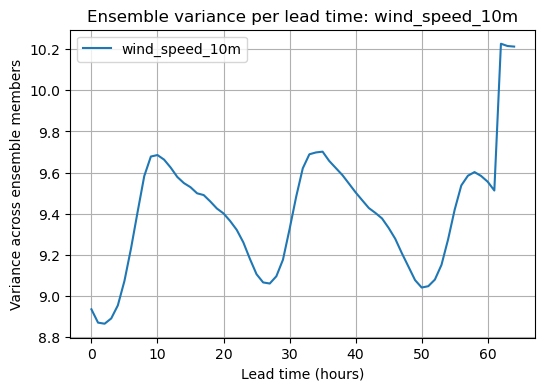

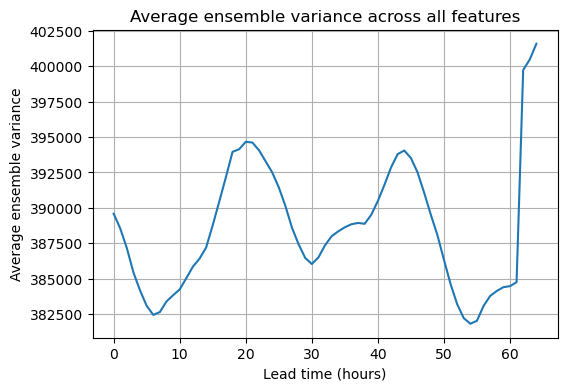

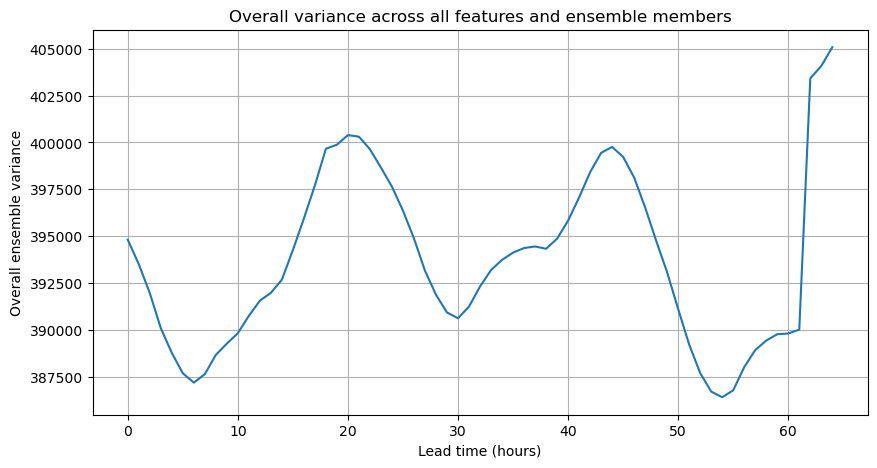

In [2]:
var_by_feature, var_overall_features, overall_variance = (
    compute_ensemble_variance_by_lead_time()
)

plot_variance_per_feature(var_by_feature)
plot_average_feature_variance(var_overall_features)
plot_overall_ensemble_variance(overall_variance)

UMM maintenance events, calculate fraction per bidding zone


In [3]:
data_path = "../data"
windpower = load_windpower(f"{data_path}/wind_power_per_bidzone.parquet")

BIDZONES = ["ELSPOT NO1", "ELSPOT NO2", "ELSPOT NO3", "ELSPOT NO4"]
capacity_factor_transformer = CapacityFactorTransformer()
maintenance_events = capacity_factor_transformer.maintenance_events.copy()


def hourly_range_inclusive(start, stop):
    return pd.date_range(start, stop, freq="h", inclusive="both")


# Pro Event: Stundenliste erzeugen, dann explodieren
maintenance_events["time"] = maintenance_events.apply(
    lambda r: hourly_range_inclusive(r["Event Start"], r["Event Stop"]), axis=1
)

maintenance_hours_long = (
    maintenance_events[["Area", "time"]]
    .explode("time")
    .drop_duplicates()
    .loc[lambda df: df["time"].isin(windpower.index)]
    .sort_values(["time", "Area"])
    .reset_index(drop=True)
)
# Zeitfenster (stündlich, inkl. beider Enden)
t0 = windpower.index.min()
t1 = windpower.index.max()
all_hours = pd.date_range(t0, t1, freq="h", inclusive="both")
total_hours = len(all_hours)
missing_in_power = all_hours.difference(windpower.index)
print(f"Missing hours in windpower: {len(missing_in_power)}")

# nur maintenance-stunden im selben fenster
mh = maintenance_hours_long.copy()
mh = mh[mh["time"].between(t0, t1)]

# Anzahl maintenance-stunden pro Area
counts = mh.groupby("Area")["time"].nunique().reindex(BIDZONES, fill_value=0)

# Ergebnis: count + fraction
maintenance_summary = (
    pd.DataFrame({"maintenance_hours": counts})
    .assign(total_hours=len(windpower.index))
    .assign(fraction=lambda d: d["maintenance_hours"] / d["total_hours"])
)

print(maintenance_summary)
print(windpower.index, len(windpower))

/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:64: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


Missing hours in windpower: 54
            maintenance_hours  total_hours  fraction
Area                                                
ELSPOT NO1               5932        46011  0.128926
ELSPOT NO2                510        46011  0.011084
ELSPOT NO3               1540        46011  0.033470
ELSPOT NO4               2710        46011  0.058899
DatetimeIndex(['2020-01-01 01:00:00+01:00', '2020-01-01 02:00:00+01:00',
               '2020-01-01 03:00:00+01:00', '2020-01-01 04:00:00+01:00',
               '2020-01-01 05:00:00+01:00', '2020-01-01 06:00:00+01:00',
               '2020-01-01 07:00:00+01:00', '2020-01-01 08:00:00+01:00',
               '2020-01-01 09:00:00+01:00', '2020-01-01 10:00:00+01:00',
               ...
               '2025-04-03 01:00:00+02:00', '2025-04-03 02:00:00+02:00',
               '2025-04-03 03:00:00+02:00', '2025-04-03 04:00:00+02:00',
               '2025-04-03 05:00:00+02:00', '2025-04-03 06:00:00+02:00',
               '2025-04-03 07:00:00+02:00', '202

In [4]:
missing_in_power = all_hours.difference(windpower.index)
extra_in_power = windpower.index.difference(all_hours)

In [5]:
len(missing_in_power), len(windpower.index), len(all_hours)

(54, 46011, 46065)

In [6]:
windparks = load_windparks("../data/windparks_bidzone.csv")

In [7]:
windparks.sort_values(by="prod_start_new")

,bidding_area,substation_name,operating_power_max,prod_start_new,eic_code
32,ELSPOT NO2,Øie,4.3,2020-01-01 00:00:00,50WP000000013430
24,ELSPOT NO2,Stokkeland,12.3,2020-01-01 00:00:00,50WP00000001609P
25,ELSPOT NO2,Storøy vindpark,6.4,2020-01-01 00:00:00,50WP00000001751M
26,ELSPOT NO2,Svåheia,24.2,2020-01-01 00:00:00,50WP00000001907H
27,ELSPOT NO2,Tellenes,160.0,2020-01-01 00:00:00,50WP000000018649
...,...,...,...,...,...
1,ELSPOT NO1,Hån Vindpark,21.0,2022-10-26 22:00:00,50WP000000022251
66,ELSPOT NO4,Kjøllefjord vindpark,40.1,2022-11-29 15:00:00,50WP00000000356X
29,ELSPOT NO2,Tonst. Vindpark,213.2,2023-03-14 09:00:00,50WP00000001720X
19,ELSPOT NO2,Skudeneshavn,5.9,2024-09-09 23:00:00,50WP00000002289C


In [8]:
windparks = load_windparks("../data/windparks_bidzone.csv")
# 1) Substation / Windpark Ebene
substation_summary = windparks.groupby(
    ["bidding_area", "substation_name"], as_index=False
).agg(
    prod_start_new=("prod_start_new", "max"),
    operating_power_max=("operating_power_max", "mean"),
    n_units=("substation_name", "size"),
)

In [9]:
substation_summary

,bidding_area,substation_name,prod_start_new,operating_power_max,n_units
0,ELSPOT NO1,Engerfjellet,2022-09-19 13:00:00,52.8,1
1,ELSPOT NO1,Hån Vindpark,2022-10-26 22:00:00,21.0,1
2,ELSPOT NO1,Kjølberget,2020-07-07 09:00:00,55.9,1
3,ELSPOT NO1,Marker Vindpark,2020-01-01 00:00:00,54.0,1
4,ELSPOT NO1,Raskiftet,2020-01-01 00:00:00,111.6,1
...,...,...,...,...,...
60,ELSPOT NO4,Raudfjell Vindpark,2020-08-31 15:00:00,84.0,1
61,ELSPOT NO4,Sørfj. Vindkraft,2020-01-01 00:00:00,96.6,1
62,ELSPOT NO4,Ånstadblåheia,2020-01-01 00:00:00,50.4,1
63,ELSPOT NO4,Øyfjell1,2021-08-23 11:00:00,172.6,1


In [10]:
# 2) Bidding Area Ebene (aus Substations!)
summary = (
    substation_summary.groupby("bidding_area")
    .agg(
        prod_start_all_operational=("prod_start_new", "max"),
        n_windparks=("substation_name", "count"),  # jetzt eindeutig!
        max_capa=("operating_power_max", "sum"),
    )
    .sort_index()
)

summary

,prod_start_all_operational,n_windparks,max_capa
bidding_area,,,
ELSPOT NO1,2022-10-26 22:00:00,6,405.7
ELSPOT NO2,2024-09-09 23:00:00,20,1451.3
ELSPOT NO3,2022-10-12 12:00:00,25,2120.4
ELSPOT NO4,2022-11-29 15:00:00,14,1160.0


weather forecast and nowcast of 4 windparks is missing

- two in NO2
- one in NO3
- one in NO4

(renaming of two in nowcast)


In [11]:
data_path = "../data"
weather_forecast = load_weather_forecast_parquet(f"{data_path}/met_forecast.parquet")
weather_nowcast = load_weather_nowcast(f"{data_path}/met_nowcast.parquet")
windpower = load_windpower(f"{data_path}/wind_power_per_bidzone.parquet")
windparks = load_windparks(f"{data_path}/windparks_bidzone.csv")
meta_parks = pd.Index(windparks["substation_name"].dropna().unique())

forecast_parks = pd.Index(weather_forecast["sid"].dropna().unique())
nowcast_parks = pd.Index(weather_nowcast["windpark"].dropna().unique())

missing_in_forecast = meta_parks.difference(forecast_parks)
missing_in_nowcast = meta_parks.difference(nowcast_parks)

missing_in_parks_f = forecast_parks.difference(meta_parks)
missing_in_parks_n = nowcast_parks.difference(meta_parks)

print(f"forecast: {missing_in_forecast, missing_in_parks_f}")
print(f"nowcast: {missing_in_nowcast, missing_in_parks_n}")

forecast: (Index(['Hinnøy', 'Håvik', 'Orkdal', 'Ramslandsvågen'], dtype='object'), Index([], dtype='object'))
nowcast: (Index(['Hinnøy', 'Håvik', 'Orkdal', 'Ramslandsvågen'], dtype='object'), Index([], dtype='object'))


In [12]:
windparks[windparks["substation_name"] == "Ramslandsvågen"]

,bidding_area,substation_name,operating_power_max,prod_start_new,eic_code
17,ELSPOT NO2,Ramslandsvågen,7.2,2020-01-01 00:00:00,50WP00000001782B


datasets start and end dates

- nowcast: '2020-01-01 01:00:00+0100' to '2025-04-01 01:00:00+0200'
- forecast: '2020-02-17 00:00:00+0100' to '2025-03-26 23:00:00+0100'
- windpower: '2020-01-01 01:00:00+0100' to '2025-04-03 10:00:00+0200'


In [13]:
data_path = "../data"
weather_forecast = load_weather_forecast_parquet(f"{data_path}/met_forecast.parquet")
weather_nowcast = load_weather_nowcast(f"{data_path}/met_nowcast.parquet")


# Keep only two day ahead entries
forecast_day = weather_forecast["time"].dt.floor("D")
ref_day_plus_2 = weather_forecast["time_ref"].dt.floor("D") + pd.Timedelta(days=2)
weather_forecast_filtered = weather_forecast.loc[forecast_day == ref_day_plus_2].copy()
print(f"After 2-day ahead filtering: {len(weather_forecast_filtered)} rows")
print(
    f"Lead time range: {weather_forecast_filtered['lt'].min():.1f}h "
    f"to {weather_forecast_filtered['lt'].max():.1f}h"
)

forecast_times = pd.Index(weather_forecast_filtered["time"].unique())
nowcast_times = weather_nowcast.index

non_overlapping_f = forecast_times.difference(nowcast_times)
non_overlapping_n = nowcast_times.difference(forecast_times)

print(non_overlapping_f, "\n", non_overlapping_n)

After 2-day ahead filtering: 2592073 rows
Lead time range: 34.0h to 61.0h
DatetimeIndex(['2024-08-21 00:00:00+02:00'], dtype='datetime64[ns, CET]', freq=None) 
 DatetimeIndex(['2020-01-01 01:00:00+01:00', '2020-01-01 02:00:00+01:00',
               '2020-01-01 03:00:00+01:00', '2020-01-01 04:00:00+01:00',
               '2020-01-01 05:00:00+01:00', '2020-01-01 06:00:00+01:00',
               '2020-01-01 07:00:00+01:00', '2020-01-01 08:00:00+01:00',
               '2020-01-01 09:00:00+01:00', '2020-01-01 10:00:00+01:00',
               ...
               '2025-03-31 16:00:00+02:00', '2025-03-31 17:00:00+02:00',
               '2025-03-31 18:00:00+02:00', '2025-03-31 19:00:00+02:00',
               '2025-03-31 20:00:00+02:00', '2025-03-31 21:00:00+02:00',
               '2025-03-31 22:00:00+02:00', '2025-03-31 23:00:00+02:00',
               '2025-04-01 00:00:00+02:00', '2025-04-01 01:00:00+02:00'],
              dtype='datetime64[ns, CET]', length=3515, freq=None)


In [14]:
weather_forecast

,sid,time_ref,time,lt,ws10m_00,ws10m_01,ws10m_02,ws10m_03,ws10m_04,ws10m_05,...,g10m_05,g10m_06,g10m_07,g10m_08,g10m_09,g10m_10,g10m_11,g10m_12,g10m_13,g10m_14
0,Engerfjellet,2020-02-15 13:00:00+01:00,2020-02-15 13:00:00+01:00,0,2.096957,2.110652,2.304629,1.942044,1.447011,2.288181,...,6.918935,8.110546,5.988888,6.934274,5.235212,5.507061,7.193576,6.753938,4.841811,4.875890
1,Engerfjellet,2020-02-15 13:00:00+01:00,2020-02-15 14:00:00+01:00,1,3.449402,3.436193,3.205872,3.450461,3.143307,4.278822,...,9.914339,9.184751,6.999992,7.892150,7.214608,8.252510,9.535547,8.717684,8.152432,6.240438
2,Engerfjellet,2020-02-15 13:00:00+01:00,2020-02-15 15:00:00+01:00,2,3.348926,2.903557,2.779971,3.733802,3.148597,2.912592,...,10.031385,8.624619,7.984353,8.264300,7.205638,9.052546,9.531441,8.367238,7.840395,7.153080
3,Engerfjellet,2020-02-15 13:00:00+01:00,2020-02-15 16:00:00+01:00,3,3.095971,2.560161,2.448126,2.267286,3.050008,3.310141,...,8.185250,8.821701,7.481009,8.172009,6.255360,7.345034,8.303812,6.735660,7.600200,7.189164
4,Engerfjellet,2020-02-15 13:00:00+01:00,2020-02-15 17:00:00+01:00,4,2.821545,2.965743,3.235484,3.212730,3.064931,2.420390,...,7.551644,9.709259,8.365305,8.703517,6.151643,10.116440,7.346225,9.079601,9.048587,6.937930
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6874207,Hamnefjell,2025-03-15 10:00:00+01:00,2025-03-18 02:00:00+01:00,64,6.872266,7.164222,6.316023,5.589070,6.980499,4.612734,...,7.563049,8.551785,9.509587,9.794330,8.066090,8.411860,10.138005,2.795730,9.581801,7.873007
6874208,Hamnefjell,2025-03-16 10:00:00+01:00,2025-03-19 02:00:00+01:00,64,16.470940,16.099072,7.887674,14.270714,4.360876,10.369994,...,14.324461,30.275700,8.210348,18.635717,10.935499,18.720608,26.935497,6.617165,21.847015,31.888178
6874209,Hamnefjell,2025-03-22 10:00:00+01:00,2025-03-25 02:00:00+01:00,64,10.446624,9.178246,12.801767,9.458190,9.951641,8.660180,...,13.481665,18.230787,13.330455,16.758130,10.482368,10.948782,14.067688,15.863382,13.946945,12.476421
6874210,Hamnefjell,2025-03-23 10:00:00+01:00,2025-03-26 02:00:00+01:00,64,18.683716,16.797531,16.638610,16.367867,17.087458,13.853215,...,19.608253,25.046673,13.443735,19.931894,24.276434,25.254436,17.580925,24.548616,27.329407,19.575188


In [ ]:
weather_forecast = weather_forecast.set_index("time")

In [ ]:
ws_cols = [col for col in weather_forecast.columns if "ws10m" in col]
ws_forecast = weather_forecast[["sid", "time_ref"] + ws_cols]

In [17]:
ws_forecast

,sid,time_ref,ws10m_00,ws10m_01,ws10m_02,ws10m_03,ws10m_04,ws10m_05,ws10m_06,ws10m_07,ws10m_08,ws10m_09,ws10m_10,ws10m_11,ws10m_12,ws10m_13,ws10m_14
time,,,,,,,,,,,,,,,,,
2020-02-15 13:00:00+01:00,Engerfjellet,2020-02-15 13:00:00+01:00,2.096957,2.110652,2.304629,1.942044,1.447011,2.288181,2.614485,2.428400,2.519852,1.792533,1.246419,3.006953,2.371769,1.975883,1.948357
2020-02-15 14:00:00+01:00,Engerfjellet,2020-02-15 13:00:00+01:00,3.449402,3.436193,3.205872,3.450461,3.143307,4.278822,3.700191,2.927215,3.316140,3.014088,3.524403,4.084505,3.629040,3.338286,2.262242
2020-02-15 15:00:00+01:00,Engerfjellet,2020-02-15 13:00:00+01:00,3.348926,2.903557,2.779971,3.733802,3.148597,2.912592,3.282750,3.259733,3.525438,2.124705,3.079855,3.423481,2.842092,3.275992,3.099485
2020-02-15 16:00:00+01:00,Engerfjellet,2020-02-15 13:00:00+01:00,3.095971,2.560161,2.448126,2.267286,3.050008,3.310141,3.675922,2.785745,3.134952,2.666179,2.923322,3.100414,2.693408,2.856006,2.281766
2020-02-15 17:00:00+01:00,Engerfjellet,2020-02-15 13:00:00+01:00,2.821545,2.965743,3.235484,3.212730,3.064931,2.420390,4.198555,3.431348,3.741955,2.366458,4.256566,2.949017,3.938569,3.954025,2.999852
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-03-18 02:00:00+01:00,Hamnefjell,2025-03-15 10:00:00+01:00,6.872266,7.164222,6.316023,5.589070,6.980499,4.612734,6.431799,6.781804,7.478519,4.952438,6.127302,7.531645,2.055379,7.380853,5.711586
2025-03-19 02:00:00+01:00,Hamnefjell,2025-03-16 10:00:00+01:00,16.470940,16.099072,7.887674,14.270714,4.360876,10.369994,22.192806,4.721727,12.933269,8.214112,12.393726,18.428535,5.222412,12.060101,21.917110
2025-03-25 02:00:00+01:00,Hamnefjell,2025-03-22 10:00:00+01:00,10.446624,9.178246,12.801767,9.458190,9.951641,8.660180,9.824086,8.725743,9.231358,7.755200,7.243185,7.969800,11.662516,6.842938,8.144165


In [ ]:
ws_forecast[ws_forecast["time_ref"] == pd.Timestamp("2020-02-15 13:00:00+01:00")]

,sid,time_ref,ws10m_00,ws10m_01,ws10m_02,ws10m_03,ws10m_04,ws10m_05,ws10m_06,ws10m_07,ws10m_08,ws10m_09,ws10m_10,ws10m_11,ws10m_12,ws10m_13,ws10m_14
time,,,,,,,,,,,,,,,,,
2020-02-15 13:00:00+01:00,Engerfjellet,2020-02-15 13:00:00+01:00,2.096957,2.110652,2.304629,1.942044,1.447011,2.288181,2.614485,2.428400,2.519852,1.792533,1.246419,3.006953,2.371769,1.975883,1.948357
2020-02-15 14:00:00+01:00,Engerfjellet,2020-02-15 13:00:00+01:00,3.449402,3.436193,3.205872,3.450461,3.143307,4.278822,3.700191,2.927215,3.316140,3.014088,3.524403,4.084505,3.629040,3.338286,2.262242
2020-02-15 15:00:00+01:00,Engerfjellet,2020-02-15 13:00:00+01:00,3.348926,2.903557,2.779971,3.733802,3.148597,2.912592,3.282750,3.259733,3.525438,2.124705,3.079855,3.423481,2.842092,3.275992,3.099485
2020-02-15 16:00:00+01:00,Engerfjellet,2020-02-15 13:00:00+01:00,3.095971,2.560161,2.448126,2.267286,3.050008,3.310141,3.675922,2.785745,3.134952,2.666179,2.923322,3.100414,2.693408,2.856006,2.281766
2020-02-15 17:00:00+01:00,Engerfjellet,2020-02-15 13:00:00+01:00,2.821545,2.965743,3.235484,3.212730,3.064931,2.420390,4.198555,3.431348,3.741955,2.366458,4.256566,2.949017,3.938569,3.954025,2.999852
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2020-02-17 22:00:00+01:00,Hamnefjell,2020-02-15 13:00:00+01:00,11.127896,7.509704,7.672300,8.926760,10.086637,12.291821,9.672620,10.864258,13.191453,8.540845,5.620414,7.656396,12.258494,9.046583,8.879390
2020-02-17 23:00:00+01:00,Hamnefjell,2020-02-15 13:00:00+01:00,10.179511,7.234228,7.784628,8.568213,11.746859,14.674846,9.702128,11.092362,12.966929,8.012280,8.455429,7.843174,11.380744,8.169752,8.128237
2020-02-18 00:00:00+01:00,Hamnefjell,2020-02-15 13:00:00+01:00,10.449562,6.991826,7.519158,8.754027,12.137137,14.301966,9.472369,10.906825,13.036092,8.673341,7.765480,6.257224,11.636466,10.057268,9.713890


In [21]:
ws_forecast

,sid,time_ref,ws10m_00,ws10m_01,ws10m_02,ws10m_03,ws10m_04,ws10m_05,ws10m_06,ws10m_07,ws10m_08,ws10m_09,ws10m_10,ws10m_11,ws10m_12,ws10m_13,ws10m_14
time,,,,,,,,,,,,,,,,,
2020-02-15 13:00:00+01:00,Engerfjellet,2020-02-15 13:00:00+01:00,2.096957,2.110652,2.304629,1.942044,1.447011,2.288181,2.614485,2.428400,2.519852,1.792533,1.246419,3.006953,2.371769,1.975883,1.948357
2020-02-15 14:00:00+01:00,Engerfjellet,2020-02-15 13:00:00+01:00,3.449402,3.436193,3.205872,3.450461,3.143307,4.278822,3.700191,2.927215,3.316140,3.014088,3.524403,4.084505,3.629040,3.338286,2.262242
2020-02-15 15:00:00+01:00,Engerfjellet,2020-02-15 13:00:00+01:00,3.348926,2.903557,2.779971,3.733802,3.148597,2.912592,3.282750,3.259733,3.525438,2.124705,3.079855,3.423481,2.842092,3.275992,3.099485
2020-02-15 16:00:00+01:00,Engerfjellet,2020-02-15 13:00:00+01:00,3.095971,2.560161,2.448126,2.267286,3.050008,3.310141,3.675922,2.785745,3.134952,2.666179,2.923322,3.100414,2.693408,2.856006,2.281766
2020-02-15 17:00:00+01:00,Engerfjellet,2020-02-15 13:00:00+01:00,2.821545,2.965743,3.235484,3.212730,3.064931,2.420390,4.198555,3.431348,3.741955,2.366458,4.256566,2.949017,3.938569,3.954025,2.999852
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-03-18 02:00:00+01:00,Hamnefjell,2025-03-15 10:00:00+01:00,6.872266,7.164222,6.316023,5.589070,6.980499,4.612734,6.431799,6.781804,7.478519,4.952438,6.127302,7.531645,2.055379,7.380853,5.711586
2025-03-19 02:00:00+01:00,Hamnefjell,2025-03-16 10:00:00+01:00,16.470940,16.099072,7.887674,14.270714,4.360876,10.369994,22.192806,4.721727,12.933269,8.214112,12.393726,18.428535,5.222412,12.060101,21.917110
2025-03-25 02:00:00+01:00,Hamnefjell,2025-03-22 10:00:00+01:00,10.446624,9.178246,12.801767,9.458190,9.951641,8.660180,9.824086,8.725743,9.231358,7.755200,7.243185,7.969800,11.662516,6.842938,8.144165


In [22]:
windpower = load_windpower(f"{data_path}/wind_power_per_bidzone.parquet")
windpower.index.min(), windpower.index.max()

(Timestamp('2020-01-01 01:00:00+0100', tz='CET'),
 Timestamp('2025-04-03 10:00:00+0200', tz='CET'))

Correlation plot wind speed and wind power per bidding zone -> information about difficulty of bidding zone


In [23]:
for i in range(1, 4):
    data_cfg = dict_to_namespace(
        {
            "dataset": "nowcast",
            "bid_zone": f"ELSPOT NO{i}",
            "split_time": "2025-01-01 00:00:00",
        }
    )
    data = load_dataset(data_cfg)

ELSPOT NO1
Loading nowcast data for ELSPOT NO1...


/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/load.py:727: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  weather_forecast["hour"] = weather_forecast.index.hour
/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:64: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


All parks operational from 2022-10-26 22:00:00
Maintenance hours in operational period: 8
Preprocessing done. X_train shape: (19122, 6, 10)
Preprocessing done. X_test shape: (2160, 6, 10)
ELSPOT NO2
Loading nowcast data for ELSPOT NO2...


/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/load.py:727: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  weather_forecast["hour"] = weather_forecast.index.hour
/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:64: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


All parks operational from 2023-03-14 09:00:00
Maintenance hours in operational period: 217
Preprocessing done. X_train shape: (15599, 18, 10)
Preprocessing done. X_test shape: (2149, 18, 10)
ELSPOT NO3
Loading nowcast data for ELSPOT NO3...


/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/load.py:727: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  weather_forecast["hour"] = weather_forecast.index.hour
/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:64: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


All parks operational from 2022-10-12 12:00:00
Maintenance hours in operational period: 451
Preprocessing done. X_train shape: (19025, 24, 10)
Preprocessing done. X_test shape: (2160, 24, 10)


In [66]:
data.keys()

dict_keys(['X_train', 'X_test', 'Y_train_cf', 'Y_train_aval', 'Y_train_gen', 'Y_test_cf', 'Y_test_aval', 'Y_test_gen', 'sites_meta', 'feature_cols', 'scaler_params', 'site_scaler_params', 'X_train_timestamps', 'X_test_timestamps'])

In [67]:
idx = data["feature_cols"].index("wind_speed_10m")
wind_speed = data["X_train"][:, :, idx]
wind_power = data["Y_train_cf"]
wind_speed_zones = []
wind_power_gen_zones = []
wind_power_cf_zones = []
scalers = []
for i in range(1, 5):
    data_cfg = dict_to_namespace(
        {
            "dataset": "nowcast",
            "bid_zone": f"ELSPOT NO{i}",
            "split_time": "2025-01-01 00:00:00",
        }
    )
    data = load_dataset(data_cfg)
    idx = data["feature_cols"].index("wind_speed_10m")

    wind_speed = data["X_train"][:, :, idx]
    wind_power_gen = data["Y_train_gen"]
    wind_power_cf = data["Y_train_cf"]

    wind_speed_zones.append(wind_speed)
    wind_power_gen_zones.append(wind_power_gen)
    wind_power_cf_zones.append(wind_power_cf)
    scalers.append(data["scaler_params"])

ELSPOT NO1
Loading nowcast data for ELSPOT NO1...


/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/load.py:727: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  weather_forecast["hour"] = weather_forecast.index.hour
/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:64: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


All parks operational from 2022-10-26 22:00:00
Maintenance hours in operational period: 8
Preprocessing done. X_train shape: (19122, 6, 10)
Preprocessing done. X_test shape: (2160, 6, 10)
ELSPOT NO2
Loading nowcast data for ELSPOT NO2...


/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/load.py:727: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  weather_forecast["hour"] = weather_forecast.index.hour
/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:64: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


All parks operational from 2023-03-14 09:00:00
Maintenance hours in operational period: 217
Preprocessing done. X_train shape: (15599, 18, 10)
Preprocessing done. X_test shape: (2149, 18, 10)
ELSPOT NO3
Loading nowcast data for ELSPOT NO3...


/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/load.py:727: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  weather_forecast["hour"] = weather_forecast.index.hour
/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:64: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


All parks operational from 2022-10-12 12:00:00
Maintenance hours in operational period: 451
Preprocessing done. X_train shape: (19025, 24, 10)
Preprocessing done. X_test shape: (2160, 24, 10)
ELSPOT NO4
Loading nowcast data for ELSPOT NO4...


/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/load.py:727: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  weather_forecast["hour"] = weather_forecast.index.hour
/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:64: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


All parks operational from 2022-11-29 15:00:00
Maintenance hours in operational period: 549
Preprocessing done. X_train shape: (17771, 13, 10)
Preprocessing done. X_test shape: (2160, 13, 10)


Spearman:

- non-parametric measure of monotonic relationship between two variables
- ranging from -1 to +1
- assesses how well relationship between variables can be described by a monotonic function (rather than assuming a linear relationship like Pearson's correlation)


11.332712
-1.5098001 5.3107285
27.279198
-1.2530507 3.5983365
27.78973
-1.3240074 4.245663
30.394327
-1.283001 3.4585738


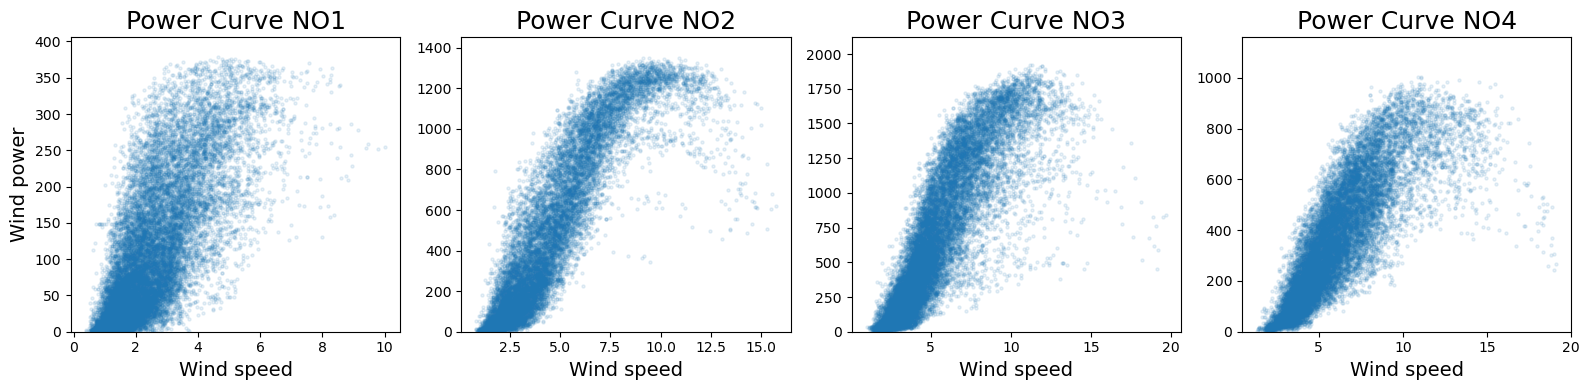

In [ ]:
fig, axes = plt.subplots(
    nrows=1, ncols=4, figsize=(4 * 4, 4), sharey=False, sharex=False
)

max_cap = [405.7, 1451.3, 2120.4, 1160.0]
for i, ax in enumerate(axes):
    _, S = wind_speed_zones[i].shape
    s = wind_speed_zones[i].mean(axis=-1)
    scaler = scalers[i]
    print(
        wind_speed_zones[i].max() * scaler["std"]["wind_speed_10m"]
        + scaler["mean"]["wind_speed_10m"]
    )
    print(s.min(), s.max())
    p = wind_power_gen_zones[i]
    scaler = scalers[i]
    s_unscaled = s * scaler["std"]["wind_speed_10m"] + scaler["mean"]["wind_speed_10m"]
    # s = wind_speed_zones[i].reshape(-1)          # (N*S,)
    # p  = np.repeat(wind_power_gen_zones[i], S)

    rho, _ = spearmanr(s, p, nan_policy="omit")

    ax.scatter(
        s_unscaled,
        p,
        s=5,
        alpha=0.1,
    )
    ax.set_title(
        f"Power Curve NO{i+1}", fontsize=18
    )  # ax.set_title(f"NO_0{i+1}\nSpearman ρ = {rho:.2f}")
    ax.set_xlabel("Wind speed", fontsize=14)
    ax.set_ylim(0, max_cap[i])


axes[0].set_ylabel("Wind power", fontsize=14)
plt.tight_layout()

plt.savefig("../plots/windpowercurves.pdf", bbox_inches="tight")

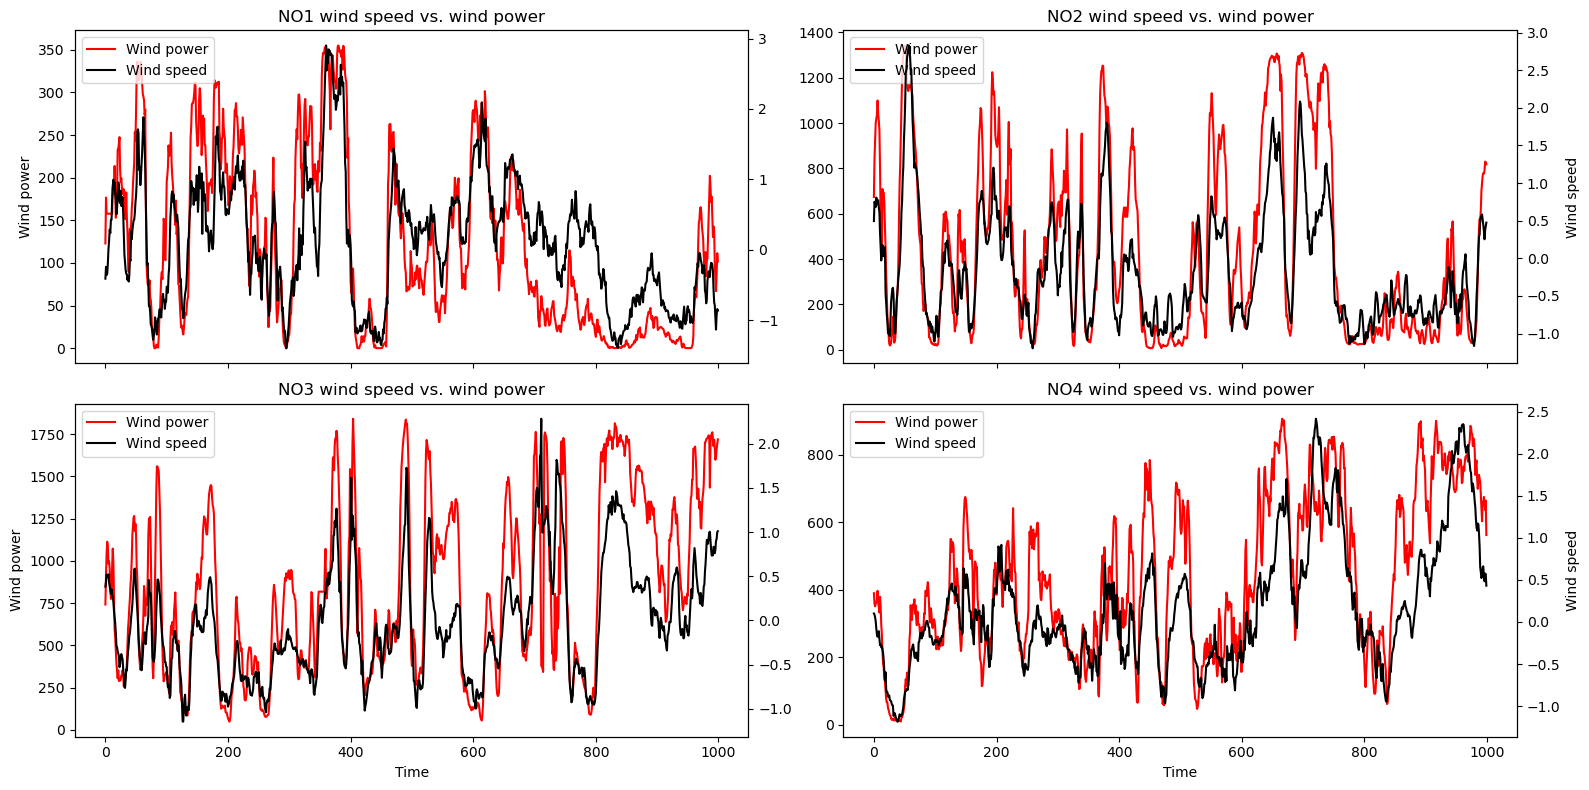

In [26]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(2, 2, figsize=(16, 8), sharex=True)

for i, ax in enumerate(axes.ravel()):
    s = wind_speed_zones[i].mean(axis=-1)[:1000]
    p = wind_power_gen_zones[i][:1000]

    x = np.arange(len(s))
    if i >= 2:
        ax.set_xlabel("Time")

    # left axis: wind power
    (l1,) = ax.plot(x, p, color="red", label="Wind power")
    if i % 2 == 0:
        ax.set_ylabel("Wind power")

    # right axis: wind speed
    ax2 = ax.twinx()
    (l2,) = ax2.plot(x, s, color="black", label="Wind speed")
    if i % 2 == 1:
        ax2.set_ylabel("Wind speed")

    # title
    ax.set_title(f"NO{i+1} wind speed vs. wind power")

    # merged legend
    ax.legend(handles=[l1, l2], loc="upper left")


plt.tight_layout()
plt.show()

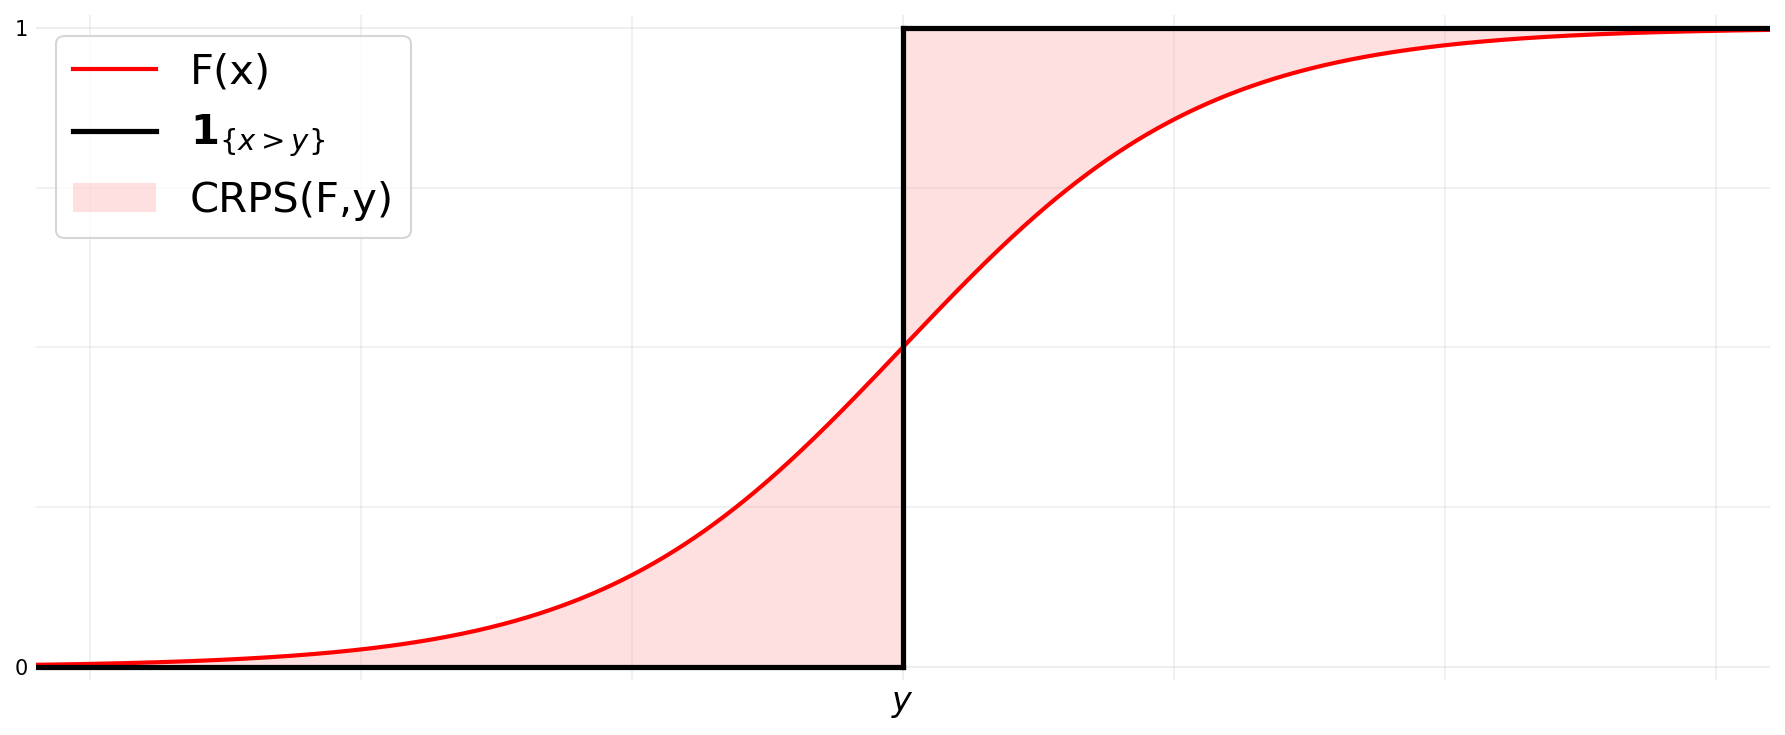

In [65]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

# --- setup ---
y = 0.0  # observation location (the vertical step)
x = np.linspace(y - 1.6, y + 1.6, 1200)

# Smooth CDF F(x): logistic CDF (S-shape)
s = 0.28
F = 1 / (1 + np.exp(-(x - y) / s))

# Indicator 1_{x>y}
I = (x > y).astype(float)

# --- plot ---
fig, ax = plt.subplots(figsize=(12, 5), dpi=150)

# F(x)
ax.plot(x, F, color="red", lw=2, label="F(x)")

# Step function
ax.plot([x.min(), y], [0, 0], color="black", lw=2.5)
ax.plot([y, y], [0, 1], color="black", lw=2.5)
ax.plot([y, x.max()], [1, 1], color="black", lw=2.5, label=r"$\mathbf{1}_{\{x>y\}}$")

# Shaded CRPS area
maskL = x <= y
ax.fill_between(x[maskL], 0, F[maskL], color="red", alpha=0.12, linewidth=0)

maskR = x >= y
ax.fill_between(
    x[maskR], F[maskR], 1, color="red", alpha=0.12, linewidth=0, label="CRPS(F,y)"
)

# --- styling ---
ax.set_ylim(-0.02, 1.02)
ax.set_xlim(x.min(), x.max())

# Major & minor locators
ax.xaxis.set_major_locator(MultipleLocator(1))
ax.xaxis.set_minor_locator(MultipleLocator(0.5))

ax.yaxis.set_major_locator(MultipleLocator(0.5))
ax.yaxis.set_minor_locator(MultipleLocator(0.25))

# Grid (major + minor)
ax.grid(True, which="major", alpha=0.25)
ax.grid(True, which="minor", alpha=0.2)

# Hide tick marks but KEEP tick locations (so minor grid works!)
ax.tick_params(which="major", length=0)
ax.tick_params(which="minor", length=0, width=0)

# Clean look
for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_yticks([0, 1])
ax.set_xticks([y])
ax.set_xticklabels([r"$y$"], fontsize=16)

plt.tight_layout()
ax.legend(fontsize=20)
plt.savefig("../plots/crps.pdf", bbox_inches="tight")

In [28]:
data_dict_zones = {}

for i in range(1, 5):
    data_cfg = dict_to_namespace(
        {
            "dataset": "nowcast",
            "bid_zone": f"ELSPOT NO{i}",
            "split_time": "2025-01-01 00:00:00",
        }
    )
    data = load_dataset(data_cfg)

    data_dict_zones[data_cfg.bid_zone] = data

ELSPOT NO1
Loading nowcast data for ELSPOT NO1...


/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/load.py:727: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  weather_forecast["hour"] = weather_forecast.index.hour
/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:64: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


All parks operational from 2022-10-26 22:00:00
Maintenance hours in operational period: 8
Preprocessing done. X_train shape: (19122, 6, 10)
Preprocessing done. X_test shape: (2160, 6, 10)
ELSPOT NO2
Loading nowcast data for ELSPOT NO2...


/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/load.py:727: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  weather_forecast["hour"] = weather_forecast.index.hour
/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:64: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


All parks operational from 2023-03-14 09:00:00
Maintenance hours in operational period: 217
Preprocessing done. X_train shape: (15599, 18, 10)
Preprocessing done. X_test shape: (2149, 18, 10)
ELSPOT NO3
Loading nowcast data for ELSPOT NO3...


/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/load.py:727: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  weather_forecast["hour"] = weather_forecast.index.hour
/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:64: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


All parks operational from 2022-10-12 12:00:00
Maintenance hours in operational period: 451
Preprocessing done. X_train shape: (19025, 24, 10)
Preprocessing done. X_test shape: (2160, 24, 10)
ELSPOT NO4
Loading nowcast data for ELSPOT NO4...


/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/load.py:727: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  weather_forecast["hour"] = weather_forecast.index.hour
/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:64: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


All parks operational from 2022-11-29 15:00:00
Maintenance hours in operational period: 549
Preprocessing done. X_train shape: (17771, 13, 10)
Preprocessing done. X_test shape: (2160, 13, 10)


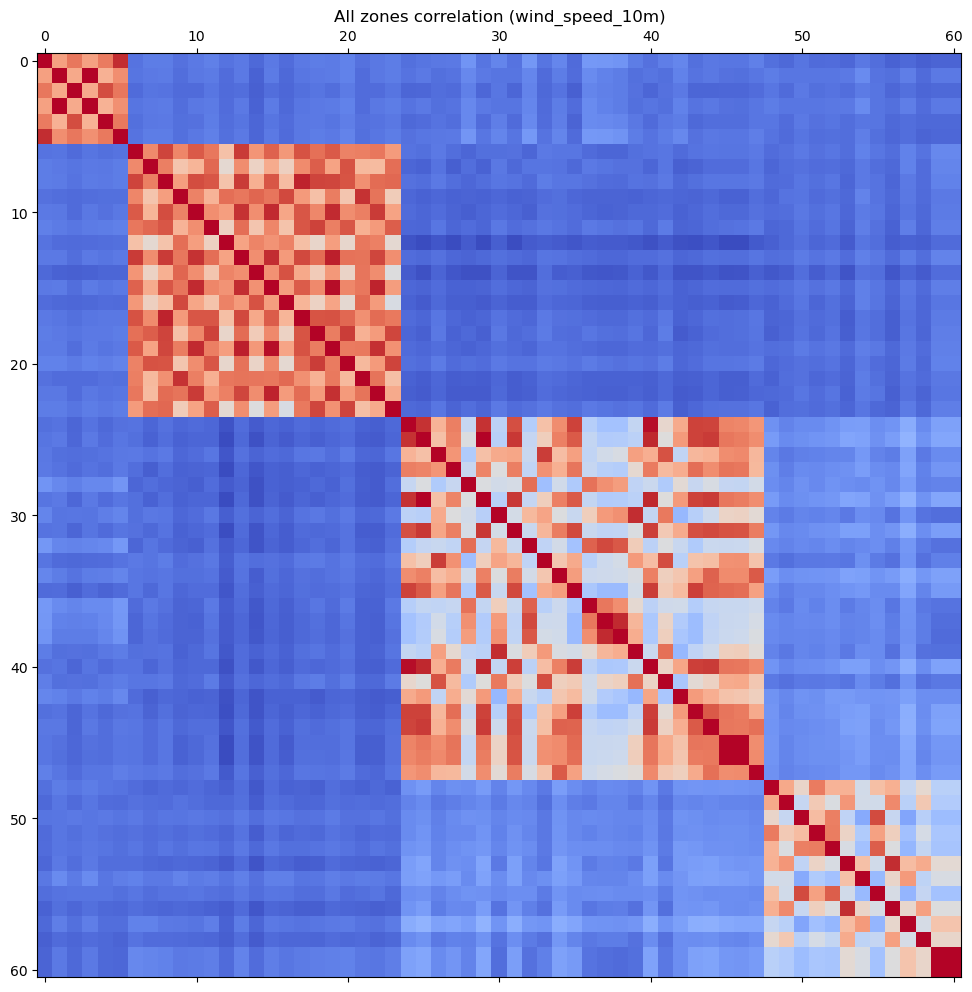

In [29]:
def correlation_across_zones_wrong(feature):
    all_dfs = []

    for z_idx, zone in enumerate(data_dict_zones.keys()):
        z_idx += 1
        X = data_dict_zones[zone]["X_train"]  # (N, S, F)

        N, S, F = X.shape

        speed_idx = data_dict_zones[zone]["feature_cols"].index(feature)

        # unnormalize
        X_all = (
            X[:, :, speed_idx] * data_dict_zones[zone]["scaler_params"]["std"][feature]
            + data_dict_zones[zone]["scaler_params"]["mean"][feature]
        )

        col_names = [f"p{p_idx}_z{z_idx}" for p_idx in range(S)]

        df_zone = pd.DataFrame(X_all, columns=col_names)

        all_dfs.append(df_zone)

    # Alle Zonen horizontal zusammenfügen
    df_all = pd.concat(all_dfs, axis=1)

    corr = df_all.corr()

    plt.figure(figsize=(14, 12))
    plt.matshow(corr, cmap="coolwarm", fignum=0)
    plt.title(f"All zones correlation ({feature})")
    plt.show()


# correlation_across_zones("air_pressure_at_sea_level")
correlation_across_zones_wrong("wind_speed_10m")
# correlation_across_zones("relative_humidity_2m")
# correlation_across_zones("air_temperature_2m")

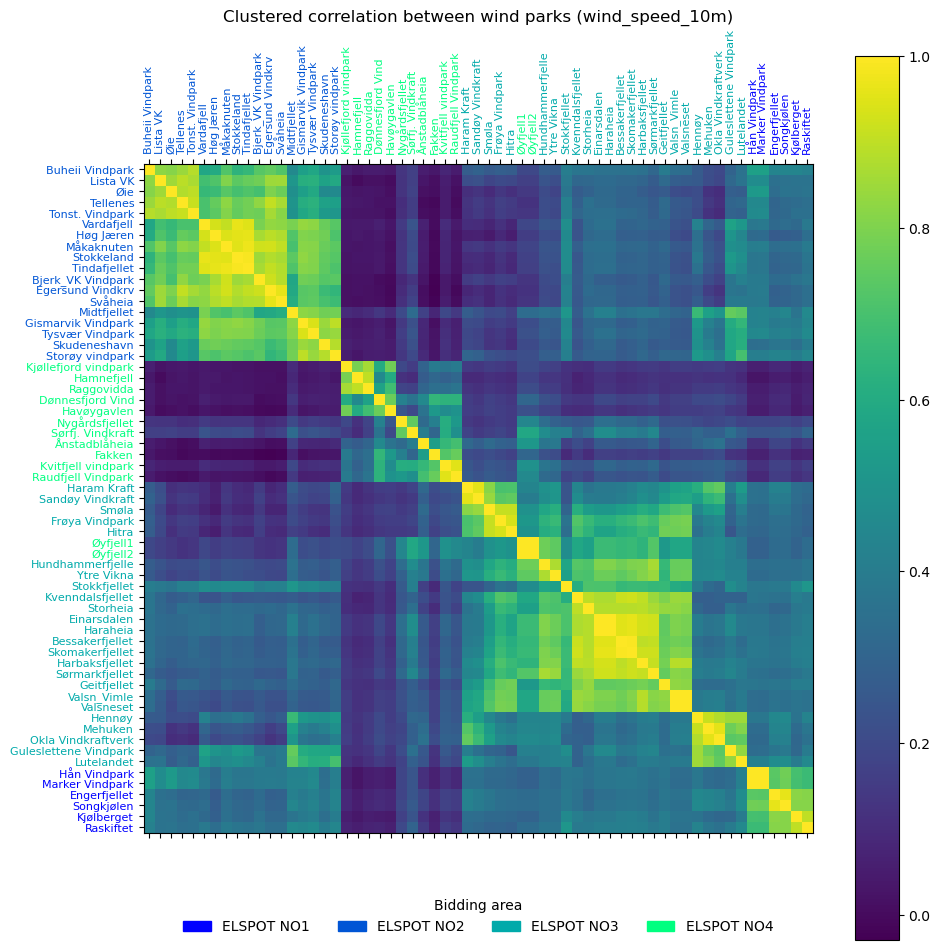

In [30]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform
import matplotlib.patches as mpatches


def correlation_across_zones(feature):
    weather_nowcast = load_weather_nowcast(f"{data_path}/met_nowcast.parquet")
    windparks = load_windparks(f"{data_path}/windparks_bidzone.csv")
    windparks_unique = (
        windparks[["bidding_area", "substation_name"]]
        .drop_duplicates()
        .set_index("substation_name")
    )
    merged = weather_nowcast.join(windparks_unique[["bidding_area"]], on="windpark")

    dfs = dict(tuple(merged[[feature, "windpark"]].groupby("windpark")))
    df = pd.DataFrame()

    for key in dfs.keys():
        df[key] = dfs[key][feature]

    x = df.to_numpy()

    # Angular similarity
    if feature == "wind_direction_10m":
        # Convert degrees to radians
        theta = np.deg2rad(df.to_numpy(dtype=float))  # shape (T, N)
        n_parks = theta.shape[1]

        # Similarity matrix S_ij = mean(cos(theta_i - theta_j))
        C = np.zeros((n_parks, n_parks), dtype=float)

        for i in range(n_parks):
            ti = theta[:, i]
            for j in range(n_parks):
                tj = theta[:, j]

                diff = ti - tj
                sim = float(np.mean(np.cos(diff)))

                C[i, j] = sim
                C[j, i] = sim

    # Pearson correlation coeffient
    else:
        C = np.corrcoef(x.T)

    # Distance
    D = 1 - C

    # Condensed form
    dist = squareform(D, checks=False)

    # Clustering
    Z = linkage(dist, method="ward")

    # Sort matrix and labels
    order = leaves_list(Z)
    C_sorted = C[np.ix_(order, order)]
    labels = df.columns.to_numpy()[order]

    zones = windparks_unique["bidding_area"].unique()
    cmap = plt.get_cmap("winter")
    colors = {z: cmap(i / (len(zones) - 1)) for i, z in enumerate(zones)}
    plt.figure(figsize=(10, 10))
    plt.matshow(C_sorted, fignum=0)
    plt.colorbar()
    plt.xticks(range(len(labels)), labels, rotation=90, fontsize=8)
    plt.yticks(range(len(labels)), labels, fontsize=8)
    ax = plt.gca()

    # X-Labels färben
    for label, tick_x, tick_y in zip(
        labels, ax.get_xticklabels(), ax.get_yticklabels()
    ):
        tick_x.set_color(colors[windparks_unique.loc[label, "bidding_area"]])
        tick_y.set_color(colors[windparks_unique.loc[label, "bidding_area"]])

    # Create legend handles
    handles = [mpatches.Patch(color=colors[z], label=z) for z in zones]

    # Add legend below plot
    ax.legend(
        handles=handles,
        title="Bidding area",
        loc="upper center",
        bbox_to_anchor=(0.5, -0.08),  # below figure
        ncol=len(zones),  # one row
        frameon=False,
    )

    plt.tight_layout()
    plt.title(f"Clustered correlation between wind parks ({feature})")
    plt.show()


data_path = "../data/"
correlation_across_zones("wind_speed_10m")

In [31]:
def distance_corrcoef(X):

    p = X.shape[1]
    C = np.empty((p, p), dtype=float)

    for i in range(p):
        C[i, i] = 1.0
        xi = X[:, i]
        for j in range(i + 1, p):
            cj = dcor.distance_correlation(xi, X[:, j])
            C[i, j] = C[j, i] = float(cj)
    return C


# Beispiel:
# X: (n_samples, n_features)
# dcorr = distance_corrcoef()

correlation_average_weather
correlation_wind_speed_10m


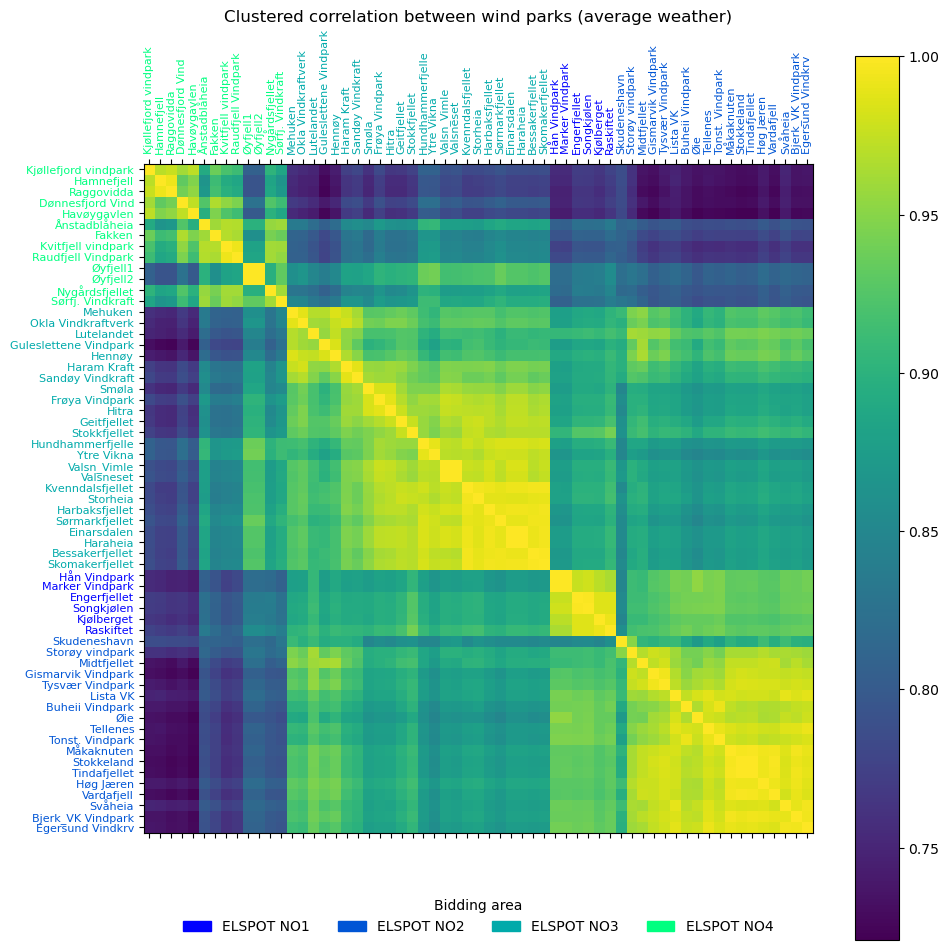

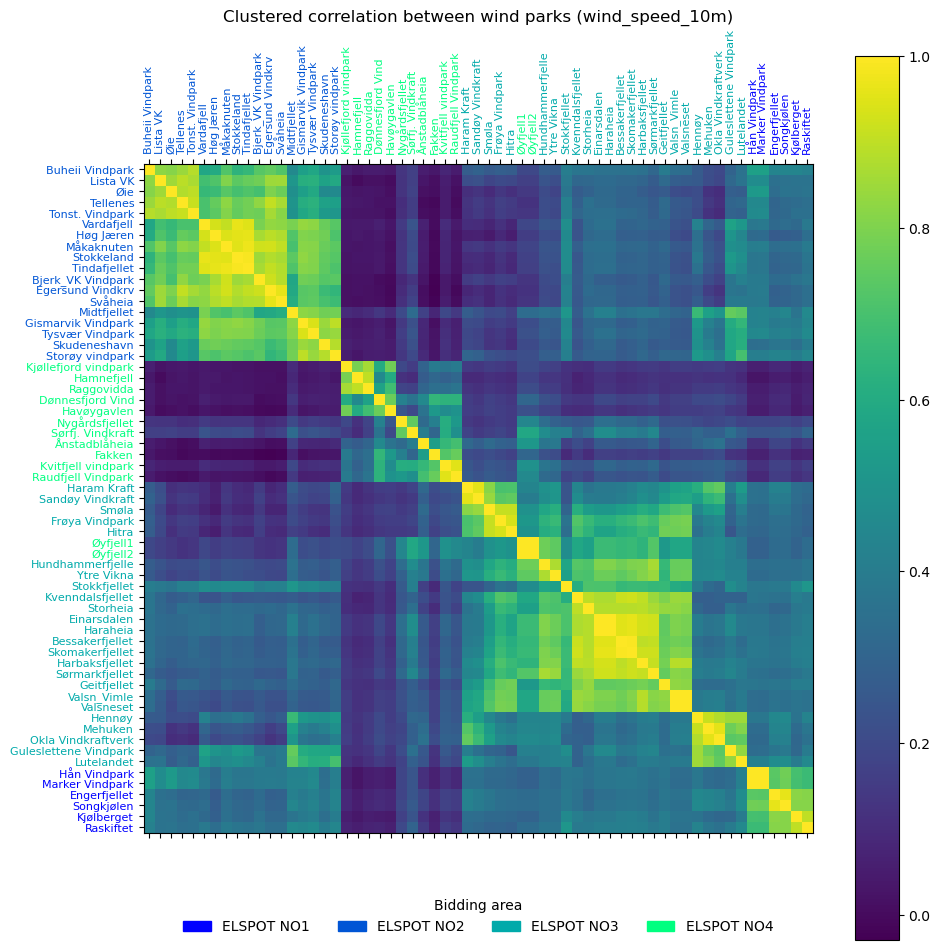

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform
import matplotlib.patches as mpatches


def correlation_across_zones(features):
    weather_nowcast = load_weather_nowcast(f"{data_path}/met_nowcast.parquet")
    windparks = load_windparks(f"{data_path}/windparks_bidzone.csv")
    windparks_unique = (
        windparks[["bidding_area", "substation_name"]]
        .drop_duplicates()
        .set_index("substation_name")
    )
    merged = weather_nowcast.join(windparks_unique[["bidding_area"]], on="windpark")
    n_parks = len(list(set(merged["windpark"].values)))

    Ds = []

    for feature in features:
        dfs = dict(tuple(merged[[feature, "windpark"]].groupby("windpark")))
        df = pd.DataFrame()

        for key in dfs.keys():
            df[key] = dfs[key][feature]

        x = df.to_numpy()

        # Angular similarity
        if feature == "wind_direction_10m":
            # Convert degrees to radians
            theta = np.deg2rad(df.to_numpy(dtype=float))  # shape (T, N)

            # Similarity matrix S_ij = mean(cos(theta_i - theta_j))
            C = np.zeros((n_parks, n_parks), dtype=float)

            for i in range(n_parks):
                ti = theta[:, i]
                for j in range(n_parks):
                    tj = theta[:, j]

                    diff = ti - tj
                    sim = float(np.mean(np.cos(diff)))

                    C[i, j] = sim
                    C[j, i] = sim

        # Pearson correlation coeffient
        else:
            C = np.corrcoef(x.T)

        # Distance
        Ds.append(1 - C)

    # weighted aggregation of different weather distances
    weights = [1 for _ in range(len(Ds))]
    D = sum(w * D for w, D in zip(weights, Ds))

    # Condensed form
    dist = squareform(D, checks=False)

    # Clustering
    Z = linkage(dist, method="ward")

    # Sort matrix and labels
    order = leaves_list(Z)
    C_sorted = C[np.ix_(order, order)]
    labels = df.columns.to_numpy()[order]

    zones = windparks_unique["bidding_area"].unique()
    cmap = plt.get_cmap("winter")
    colors = {z: cmap(i / (len(zones) - 1)) for i, z in enumerate(zones)}
    plt.figure(figsize=(10, 10))
    plt.matshow(C_sorted, fignum=0)
    plt.colorbar()
    plt.xticks(range(len(labels)), labels, rotation=90, fontsize=8)
    plt.yticks(range(len(labels)), labels, fontsize=8)
    ax = plt.gca()

    # X-Labels färben
    for label, tick_x, tick_y in zip(
        labels, ax.get_xticklabels(), ax.get_yticklabels()
    ):
        tick_x.set_color(colors[windparks_unique.loc[label, "bidding_area"]])
        tick_y.set_color(colors[windparks_unique.loc[label, "bidding_area"]])

    # Create legend handles
    handles = [mpatches.Patch(color=colors[z], label=z) for z in zones]

    # Add legend below plot
    ax.legend(
        handles=handles,
        title="Bidding area",
        loc="upper center",
        bbox_to_anchor=(0.5, -0.08),  # below figure
        ncol=len(zones),  # one row
        frameon=False,
    )

    plt.tight_layout()
    feature = "average weather" if len(features) > 2 else features[0]
    plt.title(f"Clustered correlation between wind parks ({feature})")
    file_name = "correlation_" + feature.replace(" ", "_")
    print(file_name)
    plt.savefig("../plots/" + file_name + ".pdf", bbox_inches="tight")


data_path = "../data/"
correlation_across_zones(
    [
        "wind_direction_10m",
        "wind_speed_10m",
        "air_pressure_at_sea_level",
        "relative_humidity_2m",
        "air_temperature_2m",
    ]
)
correlation_across_zones(["wind_speed_10m"])

prod_start_new
2020-01-01 00:00:00    165.6
2020-07-07 09:00:00     55.9
2021-08-24 10:00:00    110.4
2022-09-19 13:00:00     52.8
2022-10-26 22:00:00     21.0
Name: operating_power_max, dtype: float64
prod_start_new
2020-01-01 00:00:00    1288.0
2020-05-31 22:00:00     249.4
2020-08-18 08:00:00      29.4
2021-06-09 08:00:00      80.4
2021-09-29 08:00:00      12.6
2021-11-01 10:00:00      47.3
2023-03-14 09:00:00     213.2
2024-09-09 23:00:00      11.8
Name: operating_power_max, dtype: float64
prod_start_new
2020-01-01 00:00:00    826.9
2020-01-01 21:00:00      4.2
2020-01-03 23:00:00     12.6
2020-01-08 12:00:00    297.6
2020-04-14 13:00:00     58.8
2020-05-22 11:00:00    247.8
2020-05-25 06:00:00    180.6
2020-08-19 09:00:00    197.4
2020-11-12 12:00:00      1.2
2021-04-15 06:00:00     33.6
2021-08-07 09:00:00    130.2
2021-09-13 02:00:00     88.2
2021-09-27 09:00:00     51.1
2021-11-30 23:00:00     21.0
2022-10-12 12:00:00    118.8
Name: operating_power_max, dtype: float64
prod_star

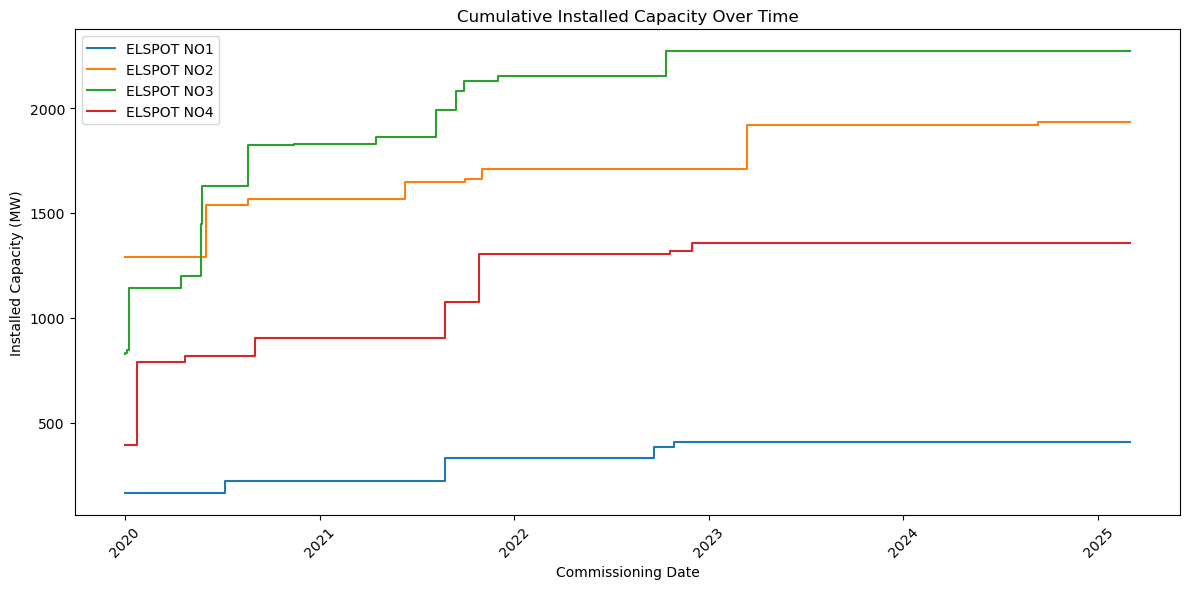

In [ ]:
windparks["prod_start_new"] = pd.to_datetime(windparks["prod_start_new"])
end_date = pd.Timestamp("2025-03-01 00:00:00")

plt.figure(figsize=(12, 6))

for bz, df in windparks.groupby("bidding_area"):
    # 1) sum capacity per commissioning timestamp (prevents stacked vertical lines)
    s = df.groupby("prod_start_new")["operating_power_max"].sum().sort_index()
    print(s)
    # 2) cumulative capacity
    cum = s.cumsum()

    # 3) add a "baseline" point just before the first timestamp (nice clean start)
    # cum = pd.concat([pd.Series([0.0], index=[cum.index.min()]), cum])

    # 4) extend flat to end_date
    if end_date > cum.index.max():
        cum.loc[end_date] = cum.iloc[-1]
        cum = cum.sort_index()

    plt.step(cum.index, cum.values, where="post", label=bz)

plt.xlabel("Commissioning Date")
plt.ylabel("Installed Capacity (MW)")
plt.title("Cumulative Installed Capacity Over Time")
plt.xticks(rotation=45)
plt.tight_layout()
plt.legend()
plt.savefig("../plots/installed_capacities.pdf", bbox_inches="tight")

In [ ]:
from configs.load_config import load_config
from types import SimpleNamespace

model_cfg = load_config("../configs/model/bnn_gen_model_nowcast_01.yaml")
data_cfg = load_config(model_cfg.data.path)
nowcast_data = load_dataset(data_cfg)
data_cfg.dataset = "forecast"
data_cfg.ensemble = SimpleNamespace(members=None, variance=False)
forecast_data = load_dataset(data_cfg)

ELSPOT NO1
Loading nowcast data for ELSPOT NO1...


/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/load.py:727: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  weather_forecast["hour"] = weather_forecast.index.hour
/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:64: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


All parks operational from 2022-10-26 22:00:00
Maintenance hours in operational period: 8
Preprocessing done. X_train shape: (19122, 6, 10)
Preprocessing done. X_test shape: (2160, 6, 10)
Loading forecast data for ELSPOT NO1, ensemble members [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]...
Loaded scaler parameters for ELSPOT NO1 and nowcast
  Saved at: 2026-03-03 08:34:40
  Split time: 2025-01-01 00:00:00+01:00
Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Renamed columns: 79
  Dropped columns: 15
  Final columns: 79

 RangeIndex(start=0, stop=6874212, step=1)
All parks operational from 2022-10-26 22:00:00
Before 2-day ahead filtering: 323718 rows
After 2-day ahead filtering: 120222 rows
Lead time range: 34.0h to 61.0h


/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:64: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


Maintenance hours in operational period: 8
Preprocessing done. X_train shape: (18132, 6, 15, 10)
Preprocessing done. X_test shape: (1895, 6, 15, 10)


In [36]:
X_train_forecast = forecast_data["X_train"]
X_train_nowcast = nowcast_data["X_train"]

In [37]:
from data_processing.utils import save_scaler_params

In [38]:
evaluation_dates = [
    "2025-09-22",
    "2025-09-23",
    "2025-09-24",
    "2025-09-25",
    "2025-09-26",
    "2025-09-29",
    "2025-09-30",
    "2025-10-01",
    "2025-10-02",
    "2025-10-03",
]


data_by_zone = {}
for bz_i in range(1, 5):
    model_cfg = load_config(f"../configs/model/bnn_gen_model_nowcast_0{bz_i}.yaml")
    data_cfg = load_config(model_cfg.data.path)
    nowcast_data = load_dataset(data_cfg)
    save_scaler_params(
        scaler_params=nowcast_data["scaler_params"],
        site_scaler_params=nowcast_data["site_scaler_params"],
        bid_zone=data_cfg.bid_zone,
        split_time=pd.Timestamp("2025-01-01 00:00:00", tz="CET"),
        dataset=data_cfg.dataset,
        dir_path="../checkpoints",
    )
    data_cfg.dataset = "forecast"
    data_cfg.ensemble = SimpleNamespace(members=None, variance=False)
    forecast_data = load_dataset(data_cfg)

    test_data = load_evaluation_forecast_data(
        dates=evaluation_dates,
        scaler_params=nowcast_data["scaler_params"],
        site_scaler_params=nowcast_data["site_scaler_params"],
        bid_zone=data_cfg.bid_zone,
        ensemble_members=None,
        variance_feature=False,
    )

    idx_standardized = [
        i
        for i, col in enumerate(nowcast_data["feature_cols"])
        if "hour" not in col and "direction" not in col
    ]
    X_train_forecast = forecast_data["X_train"]
    X_train_nowcast = nowcast_data["X_train"]
    X_train_nowcast_mean = nowcast_data["X_train"][:, :, idx_standardized].mean()
    X_train_nowcast_std = nowcast_data["X_train"][:, :, idx_standardized].std()
    X_train_forecast_mean = forecast_data["X_train"][:, :, :, idx_standardized].mean()
    X_train_forecast_std = forecast_data["X_train"][:, :, :, idx_standardized].std()

    X_val_nowcast_mean = nowcast_data["X_test"][:, :, idx_standardized].mean()
    X_val_nowcast_std = nowcast_data["X_test"][:, :, idx_standardized].std()
    X_val_forecast_mean = forecast_data["X_test"][:, :, :, idx_standardized].mean()
    X_val_forecast_std = forecast_data["X_test"][:, :, :, idx_standardized].std()

    X_test_forecast_mean = test_data["X_eval"][:, :, :, idx_standardized].mean()
    X_test_forecast_std = test_data["X_eval"][:, :, :, idx_standardized].std()

    data_by_zone[f"ELSPOT NO{bz_i}"] = {
        "Nowcast train mean": X_train_nowcast_mean,
        "Nowcast train std": X_train_nowcast_std,
        "Forecast train mean": X_train_forecast_mean,
        "Forecast train std": X_train_forecast_std,
        "Nowcast val mean": X_val_nowcast_mean,
        "Nowcast val std": X_val_nowcast_std,
        "Forecast val mean": X_val_forecast_mean,
        "Forecast val std": X_val_forecast_std,
        "Foreacst test mean": X_test_forecast_mean,
        "Forecast test std": X_test_forecast_std,
    }

ELSPOT NO1
Loading nowcast data for ELSPOT NO1...


/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/load.py:727: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  weather_forecast["hour"] = weather_forecast.index.hour
/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:64: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


All parks operational from 2022-10-26 22:00:00
Maintenance hours in operational period: 8
Preprocessing done. X_train shape: (19122, 6, 10)
Preprocessing done. X_test shape: (2160, 6, 10)
Saved scaler parameters for ELSPOT NO1: ../checkpoints/scaler_params_ELSPOT_NO1_nowcast.pkl
Loading forecast data for ELSPOT NO1, ensemble members [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]...
Loaded scaler parameters for ELSPOT NO1 and nowcast
  Saved at: 2026-03-20 10:16:29
  Split time: 2025-01-01 00:00:00+01:00
Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Renamed columns: 79
  Dropped columns: 15
  Final columns: 79

 RangeIndex(start=0, stop=6874212, step=1)
All parks operational from 2022-10-26 22:00:00
Before 2-day ahead filtering: 323718 rows
After 2-day ahead filtering: 120222 rows
Lead time range: 34.0h to 61.0h


/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:64: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


Maintenance hours in operational period: 8
Preprocessing done. X_train shape: (18132, 6, 15, 10)
Preprocessing done. X_test shape: (1895, 6, 15, 10)
Loading evaluation data for 10 dates in zone ELSPOT NO1...
Loading evaluation data for 2025-09-22 in zone ELSPOT NO1
Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Renamed columns: 79
  Dropped columns: 15
  Final columns: 79

 RangeIndex(start=0, stop=4087, step=1)
Loading evaluation data for 2025-09-23 in zone ELSPOT NO1
Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Renamed columns: 79
  Dropped columns: 15
  Final columns: 79

 RangeIndex(start=0, stop=4087, step=1)
Loading evaluation data for 2025-09-24 in zone ELSPOT NO1
Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Renamed columns: 79
  Dropped columns: 15
  Final columns: 79

 RangeIndex(start=0, stop=4087, step=1)
Loading evaluat

/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:64: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


... (16 outputs left out)

Maintenance hours in operational period: 549
Preprocessing done. X_train shape: (16878, 13, 15, 10)
Preprocessing done. X_test shape: (1895, 13, 15, 10)
Loading evaluation data for 10 dates in zone ELSPOT NO4...
Loading evaluation data for 2025-09-22 in zone ELSPOT NO4
Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Renamed columns: 79
  Dropped columns: 15
  Final columns: 79

 RangeIndex(start=0, stop=4087, step=1)
Loading evaluation data for 2025-09-23 in zone ELSPOT NO4
Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Renamed columns: 79
  Dropped columns: 15
  Final columns: 79

 RangeIndex(start=0, stop=4087, step=1)
Loading evaluation data for 2025-09-24 in zone ELSPOT NO4
Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Renamed columns: 79
  Dropped columns: 15
  Final columns: 79

 RangeIndex(start=0, stop=4087, step=1)
Loading eva

/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:64: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Renamed columns: 79
  Dropped columns: 15
  Final columns: 79

 RangeIndex(start=0, stop=4087, step=1)
Loading evaluation data for 2025-10-01 in zone ELSPOT NO4
Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Renamed columns: 79
  Dropped columns: 15
  Final columns: 79

 RangeIndex(start=0, stop=4087, step=1)
Loading evaluation data for 2025-10-02 in zone ELSPOT NO4
Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Renamed columns: 79
  Dropped columns: 15
  Final columns: 79

 RangeIndex(start=0, stop=4087, step=1)
Loading evaluation data for 2025-10-03 in zone ELSPOT NO4
Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Renamed columns: 79
  Dropped columns: 15
  Final columns: 79

 RangeIndex(start=0, stop=4087, step=1)


Maintenance hours in operational period: 0
Preprocessing done. X_eval shape: (240, 13, 15, 10)
Dropped timestamps due to maintenance: 0


In [39]:
df_data_by_zone = pd.DataFrame(data_by_zone)

In [40]:
df_data_by_zone

,ELSPOT NO1,ELSPOT NO2,ELSPOT NO3,ELSPOT NO4
Nowcast train mean,-0.000002,0.000004,-0.000002,-0.000003
Nowcast train std,0.999997,0.999996,0.999995,0.999997
Forecast train mean,-0.006019,-0.014901,0.002054,-0.009896
Forecast train std,1.011500,0.992547,0.997725,1.000578
Nowcast val mean,0.030561,-0.115644,0.121099,0.058933
Nowcast val std,1.043668,1.079430,1.105885,1.049595
Forecast val mean,0.029245,-0.134385,0.138002,0.048737
Forecast val std,1.080264,1.093713,1.129633,1.075137
Foreacst test mean,0.248557,0.507591,0.284831,0.442662
Forecast test std,1.223652,1.225134,1.158569,0.876236


In [41]:
[
    i
    for i, col in enumerate(nowcast_data["feature_cols"])
    if "hour" not in col and "direction" not in col
]

[0, 1, 4, 7, 8, 9]

In [7]:
windparks = load_windparks("../data/windparks_bidzone.csv")
windparks_unique = (
    windparks[["bidding_area", "substation_name"]]
    .drop_duplicates()
    .set_index("substation_name")
)

In [8]:
windparks

,bidding_area,substation_name,operating_power_max,prod_start_new,eic_code
0,ELSPOT NO1,Engerfjellet,52.8,2022-09-19 13:00:00,50WP00000002158R
1,ELSPOT NO1,Hån Vindpark,21.0,2022-10-26 22:00:00,50WP000000022251
2,ELSPOT NO1,Kjølberget,55.9,2020-07-07 09:00:00,50WP00000002085S
3,ELSPOT NO1,Marker Vindpark,54.0,2020-01-01 00:00:00,50WP00000002048Y
4,ELSPOT NO1,Raskiftet,111.6,2020-01-01 00:00:00,50WP00000001718K
...,...,...,...,...,...
71,ELSPOT NO4,Raudfjell Vindpark,84.0,2020-08-31 15:00:00,50WP00000001897V
72,ELSPOT NO4,Sørfj. Vindkraft,96.6,2020-01-01 00:00:00,50WP00000001770I
73,ELSPOT NO4,Ånstadblåheia,50.4,2020-01-01 00:00:00,50WP00000001916G
74,ELSPOT NO4,Øyfjell1,172.6,2021-08-23 11:00:00,50WP000000021352


In [ ]:
ignore_windpark = (
    windparks[windparks["bidding_area"].str.contains("2", case=False)]
    .sort_values("prod_start_new")
    .iloc[-1]["substation_name"]
)

In [ ]:
import sys

sys.path.append("../src")
from configs.load_config import load_config
from data_processing.load import (
    load_dataset,
    load_windparks,
    load_weather_nowcast,
    load_weather_forecast_parquet,
)
from models.build import build_model
from training.train import train_torch, sample_numpyro
import importlib
import training.evaluate as load_eval

importlib.reload(load_eval)
import matplotlib.pyplot as plt
from training.evaluate import (
    evaluate_model,
    evaluate_numpyro,
    evaluate_numpyro_on_train_set,
)
import importlib
import training.plot as load_plot

importlib.reload(load_plot)
from training.plot import (
    plot_qr_hdi_prediction,
    plot_quantile_calibration,
    plot_residuals,
    plot_qr_hdi_prediction,
    plot_quantile_calibration,
    plot_first_layer_feature_posteriors,
    plot_bnn_weight_posteriors,
    plot_posterior_predictive_vs_likelihood,
    plot_stacked_hdi_intervals,
    plot_pit_histogram,
    extract_quantile_curves,
    evaluate_and_plot_qr_ensemble_medians,
    plot_posterior_predictive_family,
    plot_qr_hdi_prediction_ensemble,
    plot_qr_hdi_prediction_ensemble_combined,
    plot_bnn_gamma_combined,
)
import torch
import numpy as np
import numpyro
from data_processing.utils import (
    load_torch_model,
    load_checkpoint,
    save_scaler_params,
    approximate_qr_intervals,
)
import pandas as pd
from types import SimpleNamespace

In [2]:
# model_cfg = load_config("../configs/model/torch_model_quantile.yaml")
# file_name = "WindPowerQuantile_weighted_2026-03-16_12-38-33_nowcast_gen_ELSPOT_NO1"
# data_cfg = load_config(model_cfg.data.path)

model_cfg = load_config("../configs/model/bnn_gen_model_nowcast_02.yaml")
data_cfg = load_config(model_cfg.data.path)

# model_cfg = load_config("../configs/model/bnn_gen_model_nowcast_03_weighted.yaml")
# data_cfg = load_config(model_cfg.data.path)
# file_name = "model_mw_gamma_extended_2026-02-16_15-32-06_nowcast_ELSPOT_NO3"  # "model_mw_gamma_extended_2026-02-16_11-27-43_nowcast_ELSPOT_NO1"

data_cfg.dataset = "forecast"
data_cfg.ensemble = SimpleNamespace(members=None, variance=False)

data = load_dataset(data_cfg)

Loading forecast data for ELSPOT NO2, ensemble members [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]...
Loaded scaler parameters for ELSPOT NO2 and nowcast
  Saved at: 2026-03-20 10:18:02
  Split time: 2025-01-01 00:00:00+01:00
Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Renamed columns: 79
  Dropped columns: 15
  Final columns: 79

 RangeIndex(start=0, stop=6874212, step=1)
All parks operational from 2023-03-14 09:00:00
Before 2-day ahead filtering: 822798 rows
After 2-day ahead filtering: 304290 rows
Lead time range: 34.0h to 61.0h


/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:64: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


Maintenance hours in operational period: 217
Preprocessing done. X_train shape: (14828, 18, 15, 10)
Preprocessing done. X_test shape: (1884, 18, 15, 10)


In [ ]:
weather_forecast = load_weather_forecast_parquet("../data/met_forecast.parquet")

In [6]:
weather_forecast

,sid,time_ref,time,lt,ws10m_00,ws10m_01,ws10m_02,ws10m_03,ws10m_04,ws10m_05,...,g10m_05,g10m_06,g10m_07,g10m_08,g10m_09,g10m_10,g10m_11,g10m_12,g10m_13,g10m_14
0,Engerfjellet,2020-02-15 13:00:00+01:00,2020-02-15 13:00:00+01:00,0,2.096957,2.110652,2.304629,1.942044,1.447011,2.288181,...,6.918935,8.110546,5.988888,6.934274,5.235212,5.507061,7.193576,6.753938,4.841811,4.875890
1,Engerfjellet,2020-02-15 13:00:00+01:00,2020-02-15 14:00:00+01:00,1,3.449402,3.436193,3.205872,3.450461,3.143307,4.278822,...,9.914339,9.184751,6.999992,7.892150,7.214608,8.252510,9.535547,8.717684,8.152432,6.240438
2,Engerfjellet,2020-02-15 13:00:00+01:00,2020-02-15 15:00:00+01:00,2,3.348926,2.903557,2.779971,3.733802,3.148597,2.912592,...,10.031385,8.624619,7.984353,8.264300,7.205638,9.052546,9.531441,8.367238,7.840395,7.153080
3,Engerfjellet,2020-02-15 13:00:00+01:00,2020-02-15 16:00:00+01:00,3,3.095971,2.560161,2.448126,2.267286,3.050008,3.310141,...,8.185250,8.821701,7.481009,8.172009,6.255360,7.345034,8.303812,6.735660,7.600200,7.189164
4,Engerfjellet,2020-02-15 13:00:00+01:00,2020-02-15 17:00:00+01:00,4,2.821545,2.965743,3.235484,3.212730,3.064931,2.420390,...,7.551644,9.709259,8.365305,8.703517,6.151643,10.116440,7.346225,9.079601,9.048587,6.937930
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6874207,Hamnefjell,2025-03-15 10:00:00+01:00,2025-03-18 02:00:00+01:00,64,6.872266,7.164222,6.316023,5.589070,6.980499,4.612734,...,7.563049,8.551785,9.509587,9.794330,8.066090,8.411860,10.138005,2.795730,9.581801,7.873007
6874208,Hamnefjell,2025-03-16 10:00:00+01:00,2025-03-19 02:00:00+01:00,64,16.470940,16.099072,7.887674,14.270714,4.360876,10.369994,...,14.324461,30.275700,8.210348,18.635717,10.935499,18.720608,26.935497,6.617165,21.847015,31.888178
6874209,Hamnefjell,2025-03-22 10:00:00+01:00,2025-03-25 02:00:00+01:00,64,10.446624,9.178246,12.801767,9.458190,9.951641,8.660180,...,13.481665,18.230787,13.330455,16.758130,10.482368,10.948782,14.067688,15.863382,13.946945,12.476421
6874210,Hamnefjell,2025-03-23 10:00:00+01:00,2025-03-26 02:00:00+01:00,64,18.683716,16.797531,16.638610,16.367867,17.087458,13.853215,...,19.608253,25.046673,13.443735,19.931894,24.276434,25.254436,17.580925,24.548616,27.329407,19.575188


In [31]:
weather_nowcast = load_weather_nowcast(f"../data/met_nowcast.parquet")

In [32]:
weather_nowcast

,air_temperature_2m,air_pressure_at_sea_level,relative_humidity_2m,precipitation_amount,wind_speed_10m,wind_direction_10m,windpark
time,,,,,,,
2020-01-01 01:00:00+01:00,276.363831,100703.859375,0.966131,3.147963,13.445930,250.681976,Bessakerfjellet
2020-01-01 02:00:00+01:00,276.951080,100595.609375,0.972677,3.636308,13.807796,251.660736,Bessakerfjellet
2020-01-01 03:00:00+01:00,277.113007,100526.656250,0.964682,1.921109,15.788631,250.626617,Bessakerfjellet
2020-01-01 04:00:00+01:00,277.259033,100408.359375,0.966498,1.919362,16.493980,254.728180,Bessakerfjellet
2020-01-01 05:00:00+01:00,277.229248,100421.062500,0.964835,1.275917,16.933884,253.571869,Bessakerfjellet
...,...,...,...,...,...,...,...
2025-03-31 21:00:00+02:00,271.956329,101966.796875,0.962775,1.563930,8.735393,196.803040,Øyfjell2
2025-03-31 22:00:00+02:00,271.778442,101946.859375,0.995688,0.375011,11.672383,206.363098,Øyfjell2
2025-03-31 23:00:00+02:00,271.601746,101986.929688,0.993568,0.034405,10.683748,209.511871,Øyfjell2


In [ ]:
windparks

In [33]:
weather_nowcast[weather_nowcast["windpark"] != ignore_windpark]

,air_temperature_2m,air_pressure_at_sea_level,relative_humidity_2m,precipitation_amount,wind_speed_10m,wind_direction_10m,windpark
time,,,,,,,
2020-01-01 01:00:00+01:00,276.363831,100703.859375,0.966131,3.147963,13.445930,250.681976,Bessakerfjellet
2020-01-01 02:00:00+01:00,276.951080,100595.609375,0.972677,3.636308,13.807796,251.660736,Bessakerfjellet
2020-01-01 03:00:00+01:00,277.113007,100526.656250,0.964682,1.921109,15.788631,250.626617,Bessakerfjellet
2020-01-01 04:00:00+01:00,277.259033,100408.359375,0.966498,1.919362,16.493980,254.728180,Bessakerfjellet
2020-01-01 05:00:00+01:00,277.229248,100421.062500,0.964835,1.275917,16.933884,253.571869,Bessakerfjellet
...,...,...,...,...,...,...,...
2025-03-31 21:00:00+02:00,271.956329,101966.796875,0.962775,1.563930,8.735393,196.803040,Øyfjell2
2025-03-31 22:00:00+02:00,271.778442,101946.859375,0.995688,0.375011,11.672383,206.363098,Øyfjell2
2025-03-31 23:00:00+02:00,271.601746,101986.929688,0.993568,0.034405,10.683748,209.511871,Øyfjell2


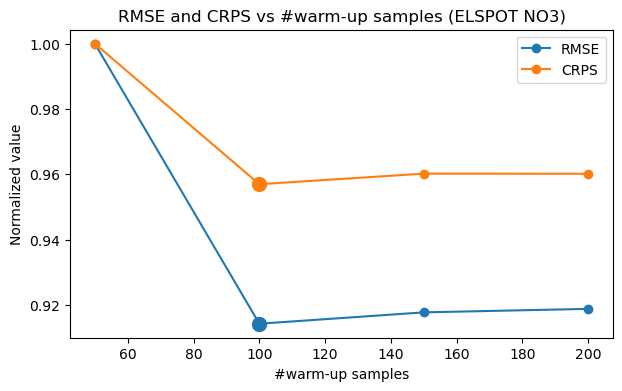

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

results = [
    {"warm-up samples": 50, "rmse": 215.385, "crps": 106.483},
    {"warm-up samples": 100, "rmse": 196.922, "crps": 101.903},
    {"warm-up samples": 150, "rmse": 197.671, "crps": 102.248},
    {"warm-up samples": 200, "rmse": 197.902, "crps": 102.244},
]

# Extract values
samples = [r["warm-up samples"] for r in results]
rmse = [r["rmse"] for r in results]
crps = [r["crps"] for r in results]


idx = list(samples).index(100)

# Plot
plt.figure(figsize=(7, 4))
plt.plot(samples, rmse / np.max(rmse), marker="o", label="RMSE")
plt.plot(samples, crps / np.max(crps), marker="o", label="CRPS")

# Highlight final value
plt.scatter(samples[idx], rmse[idx] / np.max(rmse), s=100, zorder=3)
plt.scatter(samples[idx], crps[idx] / np.max(crps), s=100, zorder=3)

plt.xlabel("#warm-up samples")
plt.ylabel("Normalized value")
plt.title("RMSE and CRPS vs #warm-up samples (ELSPOT NO3)")
plt.legend()

plt.savefig("../plots/warm-up-samples.pdf")